# 10 · Advanced model benchmarking

## Purpose

Compare traditional ensembles, histogram boosting, and installed modern gradient-boosting candidates under the shared validation folds.

## Method

Benchmark Random Forest, Extra Trees, HistGradientBoosting, CatBoost, LightGBM, XGBoost, and eligible TabPFN. Quick mode uses three folds, bounded estimator counts, one thread per candidate, and per-candidate checkpoints; unavailable or failed packages are reported.

## Interpretation

Use the displayed tables, figures, and saved metrics produced by this run. Do not fill this section with assumed outcomes. For every result, distinguish observed evidence from interpretation.

## Limitations

Runtime and process RSS changes depend on the machine. Optional model families can be omitted for installation, incompatibility, or resource reasons; no model is assumed to win.

## References

Model papers and eligibility notes: docs/references.md


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'returnwise').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display
from returnwise.research_state import load_state, save_state
state = load_state()
print('Project:', ROOT)
print('Notebook:', '10 · Advanced model benchmarking')


Project: C:\Users\Lenovo\Documents\Who is back
Notebook: 10 · Advanced model benchmarking


Checkpointed Random forest; available RAM: 1.39 GiB


Checkpointed Extra trees; available RAM: 1.12 GiB


Checkpointed HistGradientBoosting; available RAM: 1.22 GiB


,model,folds,roc_auc,pr_auc,accuracy,balanced_accuracy,precision,recall,f1,roc_auc_std,pr_auc_std,accuracy_std,balanced_accuracy_std,precision_std,recall_std,f1_std,mean_fit_seconds,mean_inference_seconds,mean_rss_delta_mb,status
0,Random forest,3,0.552879,0.520752,0.541087,0.538170,0.517795,0.480753,0.498581,0.001457,0.000286,0.001240,0.001253,0.001407,0.004018,0.002382,9.266771,0.691674,107.225260,completed
1,Extra trees,3,0.563745,0.530606,0.545431,0.544025,0.521299,0.516349,0.518811,0.000440,0.000245,0.000889,0.000931,0.000914,0.002570,0.001602,7.821213,0.705412,110.040365,completed
2,HistGradientBoosting,3,0.585704,0.551442,0.563144,0.555814,0.553648,0.411562,0.472031,0.003985,0.002219,0.003624,0.002961,0.007090,0.010840,0.004690,2.331395,0.412806,0.748698,completed


,model,fold,roc_auc,pr_auc,accuracy,balanced_accuracy,precision,recall,f1,confusion_matrix_tn_fp_fn_tp,fit_seconds,inference_seconds,rss_delta_mb,status
0,Random forest,1,0.551306,0.520427,0.541943,0.539197,0.518625,0.485145,0.501327,"[16624, 11398, 13032, 12280]",9.431860,0.691038,112.609375,completed
1,Random forest,2,0.554183,0.520968,0.541653,0.538539,0.518588,0.477263,0.497068,"[16808, 11214, 13231, 12080]",9.267032,0.694754,106.070312,completed
2,Random forest,3,0.553148,0.520860,0.539666,0.536775,0.516170,0.479851,0.497349,"[16636, 11385, 13166, 12146]",9.101420,0.689232,102.996094,completed
3,Extra trees,1,0.564144,0.530835,0.546424,0.545087,0.522294,0.518766,0.520524,"[16012, 12010, 12181, 13131]",8.195867,0.645324,111.203125,completed
4,Extra trees,2,0.563274,0.530348,0.545160,0.543635,0.521103,0.513650,0.517350,"[16074, 11948, 12310, 13001]",7.671360,0.794042,111.769531,completed
5,Extra trees,3,0.563816,0.530635,0.544710,0.543352,0.520498,0.516632,0.518558,"[15974, 12047, 12235, 13077]",7.596413,0.676868,107.148438,completed
6,HistGradientBoosting,1,0.581121,0.548912,0.559043,0.552428,0.545807,0.422250,0.476144,"[19128, 8894, 14624, 10688]",2.283809,0.321246,1.847656,completed
7,HistGradientBoosting,2,0.587646,0.552356,0.565916,0.557918,0.559609,0.400577,0.466923,"[20043, 7979, 15172, 10139]",2.394664,0.554043,0.000000,completed
8,HistGradientBoosting,3,0.588346,0.553058,0.564472,0.557095,0.555526,0.411860,0.473025,"[19680, 8341, 14887, 10425]",2.315712,0.363130,0.398438,completed


Optional candidates skipped or failed: {'CatBoost': 'Optional dependency `catboost` is not installed.', 'LightGBM': 'Optional dependency `lightgbm` is not installed.', 'XGBoost': 'Optional dependency `xgboost` is not installed.', 'TabPFN': 'Optional dependency `tabpfn` is not installed.'}


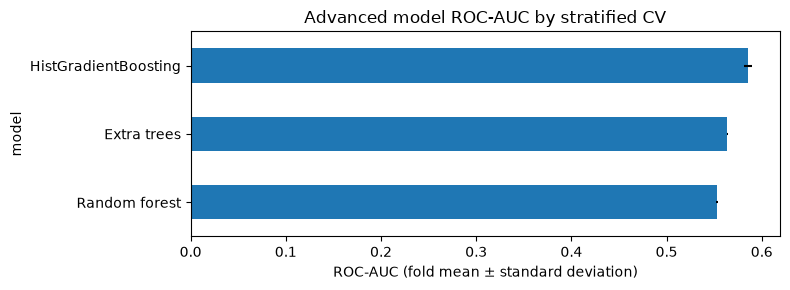

In [2]:
from returnwise.models import benchmark_models, model_registry
from returnwise.research_state import load_state, save_state
import gc
import matplotlib.pyplot as plt
import pandas as pd
import psutil

state = load_state()
if 'X_train' not in state:
    raise RuntimeError('Run notebook 07 first.')
mode = state.get('experiment_mode', 'quick')
if mode != 'quick':
    raise RuntimeError('This resource-managed run requires the verified Quick mode.')
advanced_names = ['Random forest', 'Extra trees', 'HistGradientBoosting', 'CatBoost', 'LightGBM', 'XGBoost', 'TabPFN']
available, advanced_skipped = model_registry(state['X_train'], mode=mode)
advanced_results = state.get('advanced_results', pd.DataFrame())
advanced_folds = state.get('advanced_folds', pd.DataFrame())
done = set(advanced_results.loc[advanced_results['status'].isin(['completed', 'failed']), 'model']) if not advanced_results.empty else set()
for name in advanced_names:
    if name in done:
        continue
    if name not in available:
        advanced_skipped[name] = advanced_skipped.get(name, 'Unavailable in the active model registry.')
        continue
    result, fold_result, skipped = benchmark_models(
        state['X_train'], state['y_train'], mode=mode, model_names=[name]
    )
    advanced_results = pd.concat([advanced_results, result], ignore_index=True)
    advanced_folds = pd.concat([advanced_folds, fold_result], ignore_index=True)
    advanced_skipped.update(skipped)
    state.update({'advanced_results': advanced_results, 'advanced_folds': advanced_folds,
                  'advanced_skipped': advanced_skipped})
    save_state(state)
    done.add(name)
    del result, fold_result
    gc.collect()
    available_gb = psutil.virtual_memory().available / (1024 ** 3)
    print(f'Checkpointed {name}; available RAM: {available_gb:.2f} GiB')
    if available_gb < 0.45:
        raise RuntimeError(f'Stopping after {name}: available RAM fell below 0.45 GiB.')
display(advanced_results)
display(advanced_folds)
print('Optional candidates skipped or failed:', advanced_skipped)
completed = advanced_results[advanced_results['status'] == 'completed']
if not completed.empty:
    ax = completed.sort_values('roc_auc').plot.barh(x='model', y='roc_auc', xerr='roc_auc_std', figsize=(8, max(3, len(completed) * 0.45)), legend=False, title='Advanced model ROC-AUC by stratified CV')
    ax.set_xlabel('ROC-AUC (fold mean ± standard deviation)')
    plt.tight_layout()
    plt.show()
state.update({'advanced_results': advanced_results, 'advanced_folds': advanced_folds,
              'advanced_skipped': advanced_skipped})
from returnwise.experiments import log_experiment
log_experiment('Advanced model benchmark', None,
               {'results': advanced_results.to_dict(orient='records'), 'skipped': advanced_skipped},
               {'mode': state.get('experiment_mode', 'quick')})
save_state(state)
